# Exercise 8 – The Metropolis algorithm

**Week 2 · Monte Carlo sampling**

Instead of independent samples, the Metropolis algorithm builds a chain: from
the current position $x$ propose $x'$ and accept it with probability
$\min\!\big(1, e^{-(V(x')-V(x))/k_BT}\big)$; otherwise stay at $x$. The chain
samples the Boltzmann distribution once it is long enough.

Two kinds of proposals are compared for the harmonic potential:

* **random walk**: $x' = x + \delta\cdot\mathcal{N}(0,1)$, for two step sizes $\delta$,
* **uniform**: $x'$ drawn uniformly in $[-3, 3]$, independent of $x$.

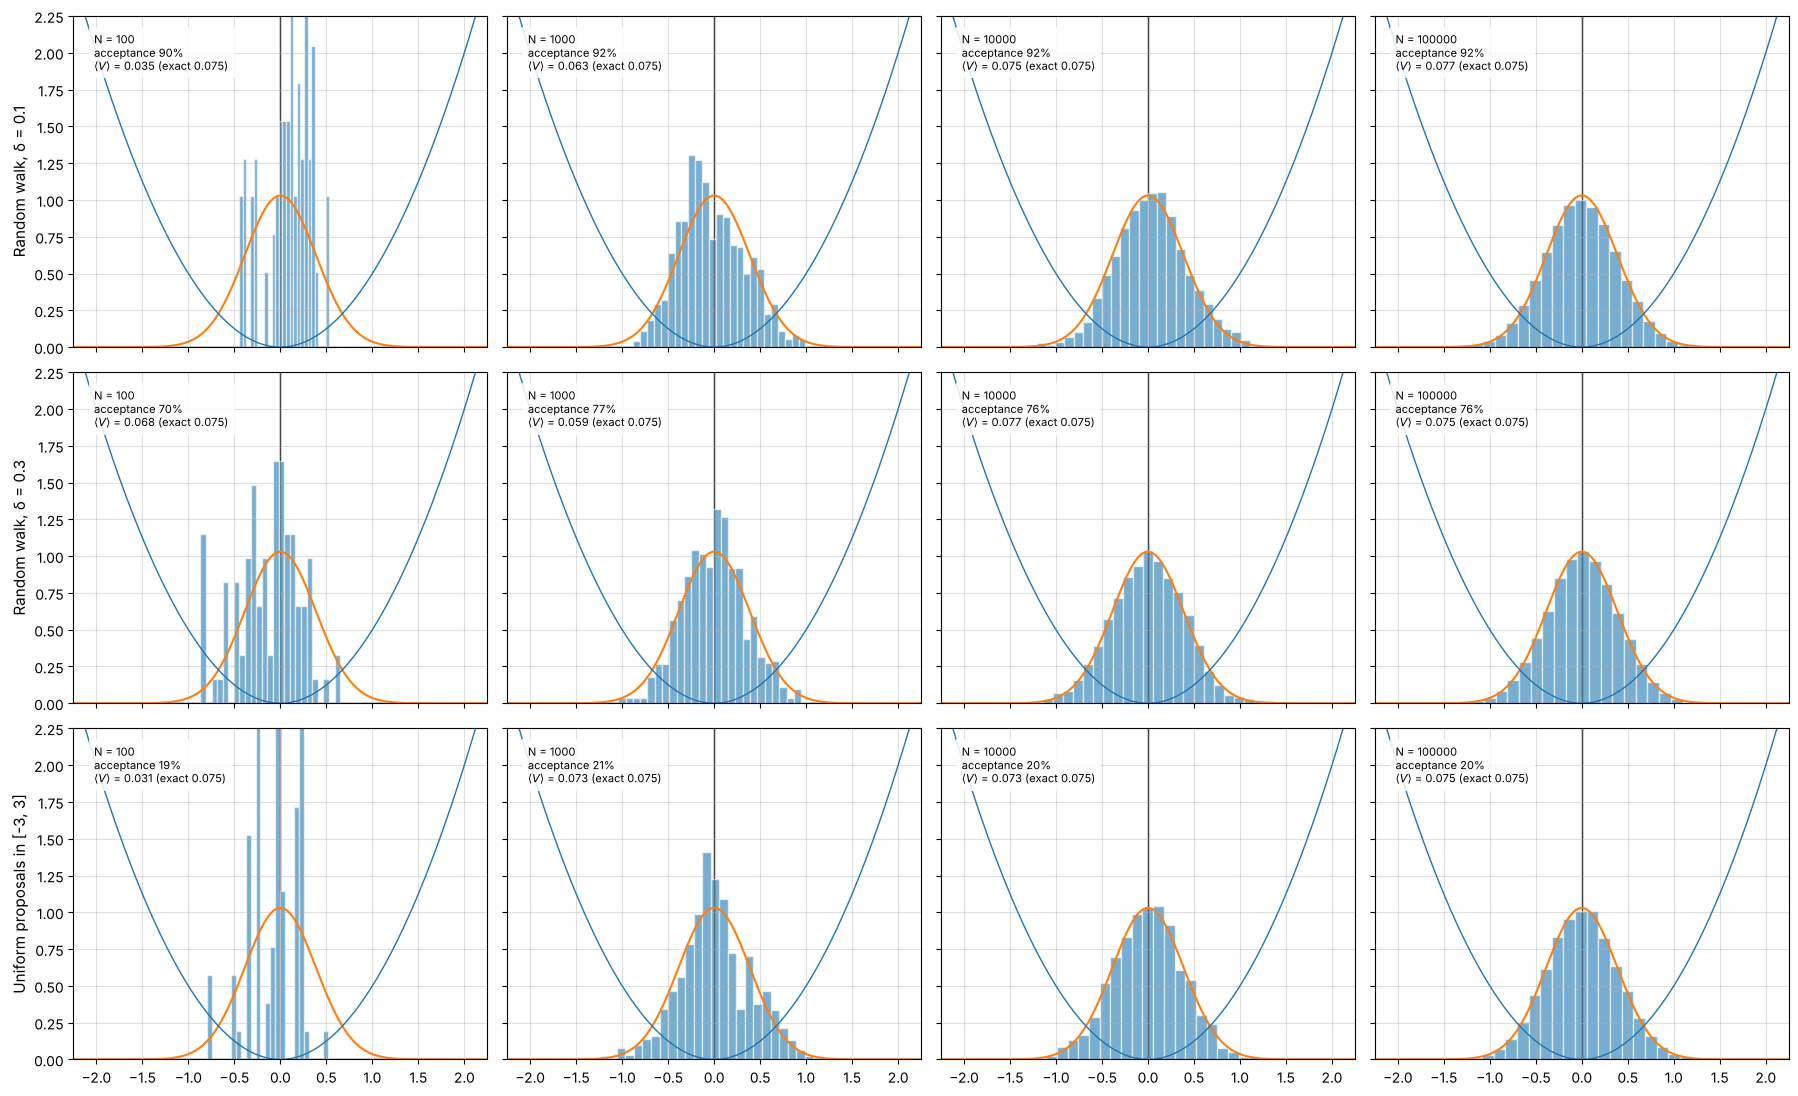

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.montecarlo import boltzmann_pdf, metropolis, thermal_average
from comphy.plotting import annotate, setup_axes

rng = np.random.default_rng(0)
V = lambda x: 0.5 * np.asarray(x) ** 2
kT, lims = 0.15, (-3, 3)
xs = np.linspace(-2.25, 2.25, 400)
pdf = boltzmann_pdf(V, kT, lims)
exact = thermal_average(V, kT, lims)
sizes = [100, 1_000, 10_000, 100_000]

proposals = {"Random walk, δ = 0.1": dict(step=0.1), "Random walk, δ = 0.3": dict(step=0.3),
             "Uniform proposals in [-3, 3]": dict(lims=lims)}

fig, axes = plt.subplots(3, 4, figsize=(18, 11), sharex=True, sharey=True)
for row, (name, kwargs) in zip(axes, proposals.items()):
    for ax, n in zip(row, sizes):
        sample, acc = metropolis(V, kT, x0=0.0, n_steps=n, rng=rng, **kwargs)
        ax.hist(sample, bins=25, density=True, color="C0", alpha=0.6, edgecolor="white")
        ax.plot(xs, pdf(xs), color="C1")
        ax.plot(xs, V(xs), color="C0", lw=1)
        annotate(ax, f"N = {n}\nacceptance {acc:.0%}\n$\\langle V\\rangle$ = {V(sample).mean():.3f} "
                     f"(exact {exact:.3f})", fontsize=8)
        setup_axes(ax, xlim=(-2.25, 2.25), ylim=(0, 2.25), xlabel=None, ylabel=None)
    row[0].set_ylabel(name, fontsize=11)
fig.tight_layout()
plt.show()

With small steps nearly every move is accepted, but the chain moves slowly
and short chains have not yet explored the distribution. Uniform proposals
are often rejected (most of $[-3,3]$ is energetically unfavourable) but each
accepted move is a big jump. For long chains all three converge to the exact
distribution.

## A look at the chain itself

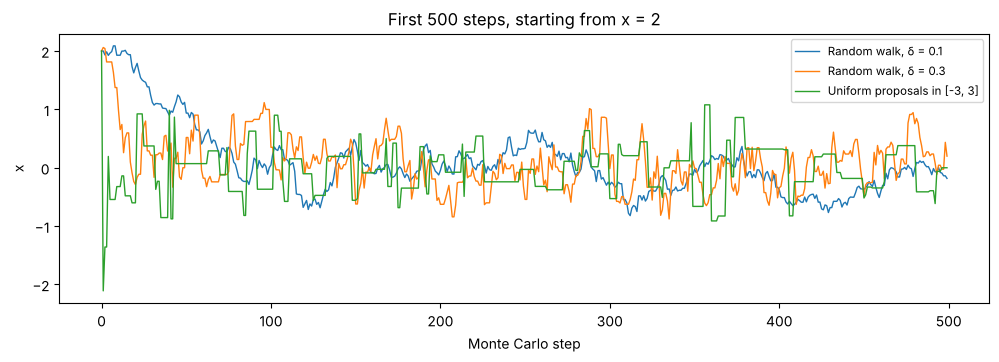

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for name, kwargs in proposals.items():
    chain, _ = metropolis(V, kT, x0=2.0, n_steps=500, rng=rng, **kwargs)
    ax.plot(chain, label=name, lw=1)
ax.set(xlabel="Monte Carlo step", ylabel="x", title="First 500 steps, starting from x = 2")
ax.legend(fontsize="small")
plt.show()